# Bank Marketing: will a customer subscribe to a term deposit?

>Data: `data/train.csv`, the UCI Bank Marketing data (45,211 phone calls, semicolon-separated). The target `y` says whether the customer subscribed.
>
>Output: a scikit-learn pipeline and a decision threshold, saved by the last cell into `backend-api/models/` and `backend-api/config/`. The API loads exactly these two files.
>
>Run it from the `notebook/` folder with the versions pinned in `backend-api/requirements.txt` (numpy 2.4.6, scikit-learn 1.6.1), plus matplotlib and Jupyter. A pickle can only be loaded by the scikit-learn version that wrote it.

In [1]:
import json
import pickle
import platform
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, confusion_matrix,
                             f1_score, log_loss, precision_recall_curve, roc_auc_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold, TimeSeriesSplit,
                                     cross_val_predict, cross_validate, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42

# OneHotEncoder(handle_unknown="ignore") is deliberate: the early slices of the file have never seen some
# values (for example later months), and scikit-learn warns on every such fold. Silence only that message.
warnings.filterwarnings("ignore", message="Found unknown categories")

# Chart style: one blue for the main series, orange for the comparison, aqua for a third,
# hairline grid, no top/right frame.
INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "figure.dpi": 100, "legend.frameon": False,
})

print(f"python {platform.python_version()}, numpy {np.__version__}, "
      f"pandas {pd.__version__}, scikit-learn {sklearn.__version__}")

python 3.11.9, numpy 2.4.6, pandas 2.3.3, scikit-learn 1.6.1


# 1. Data

In [2]:
DATA_PATH = next((p for p in (Path("../data/train.csv"), Path("data/train.csv")) if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("train.csv not found in ../data/ or data/")

df = pd.read_csv(DATA_PATH, sep=";")
y = (df["y"] == "yes").astype(int)
base_rate = y.mean()

print(f"{DATA_PATH}: {df.shape[0]:,} rows, {df.shape[1]} columns, {df.isna().sum().sum()} missing values")
print(f"yes: {y.sum():,} of {len(y):,} ({base_rate:.1%}). "
      f"Always answering 'no' is {1 - base_rate:.1%} accurate, so accuracy is not a useful metric here.")
df.head()

..\data\train.csv: 45,211 rows, 17 columns, 0 missing values
yes: 5,289 of 45,211 (11.7%). Always answering 'no' is 88.3% accurate, so accuracy is not a useful metric here.


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


# 2. Exploratory data analysis

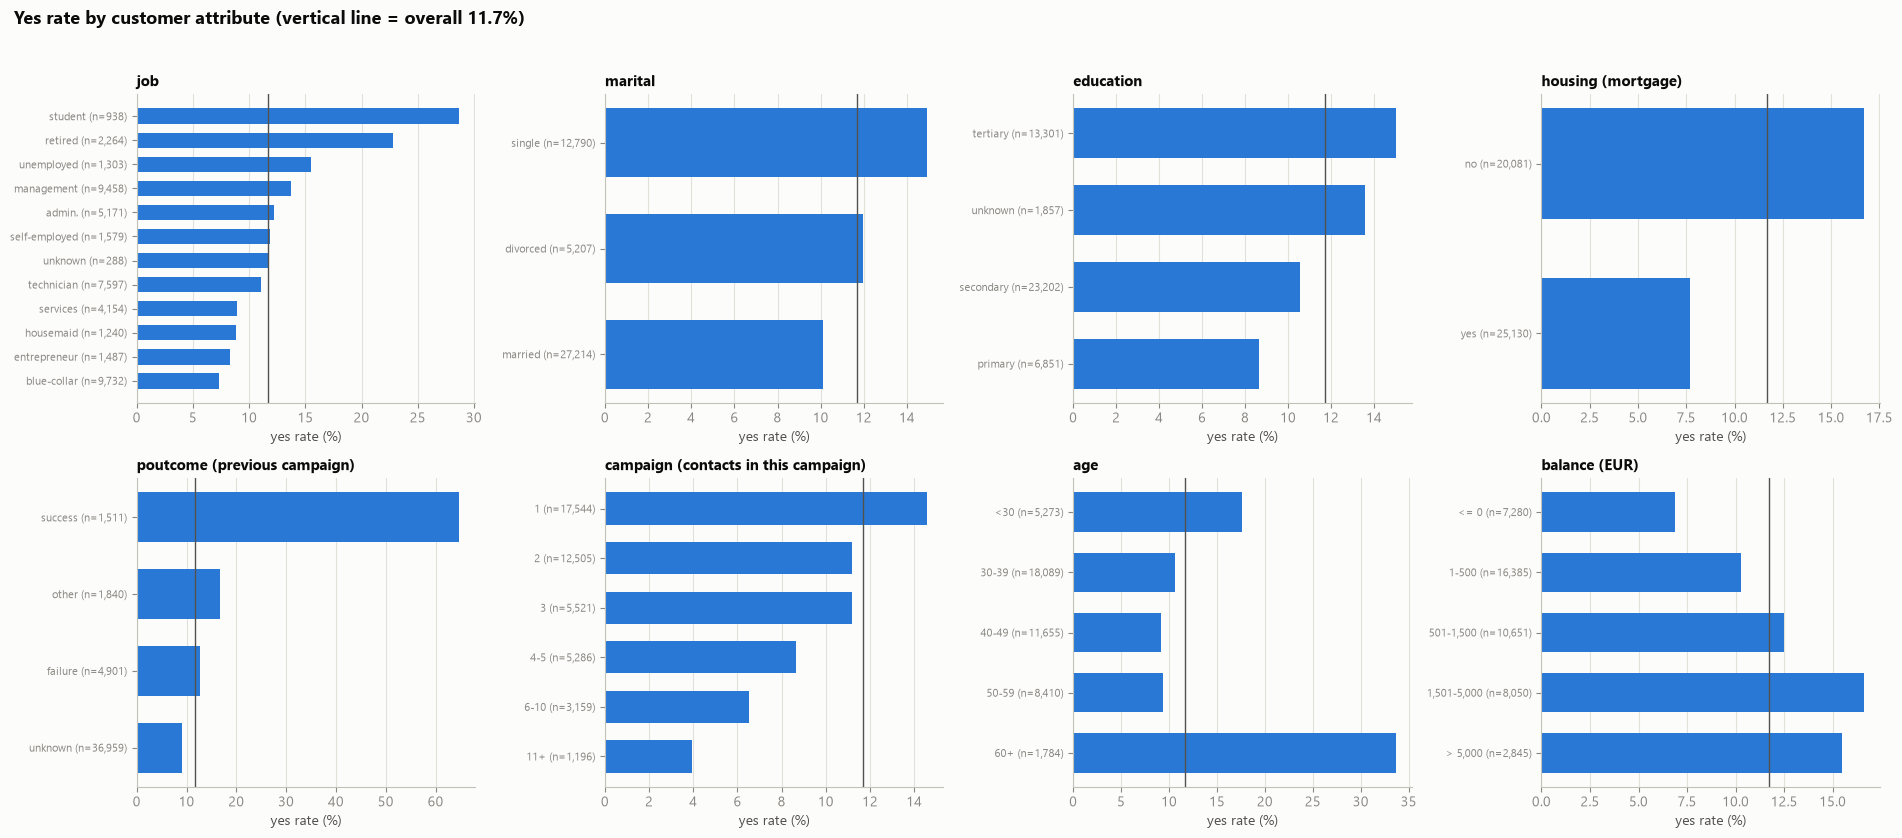

In [3]:
def yes_rate_by(series):
    """Yes rate and row count for each value of a (categorical or binned) series."""
    return y.groupby(series, observed=True).agg(rate="mean", n="size")


def rate_panel(ax, table, title, sort=True):
    """Horizontal bars of yes rate; the row count sits in the tick label."""
    if sort:
        table = table.sort_values("rate")
    ax.barh([f"{label} (n={n:,})" for label, n in zip(table.index, table["n"])],
            table["rate"] * 100, color=BLUE, height=0.65)
    ax.axvline(base_rate * 100, color=INK_2, lw=1)
    if not sort:
        ax.invert_yaxis()  # ordered bins read top to bottom
    ax.set_title(title)
    ax.set_xlabel("yes rate (%)")
    ax.tick_params(axis="y", labelsize=8)
    ax.grid(axis="y", visible=False)


panels = [
    ("job", yes_rate_by(df["job"]), True),
    ("marital", yes_rate_by(df["marital"]), True),
    ("education", yes_rate_by(df["education"]), True),
    ("housing (mortgage)", yes_rate_by(df["housing"]), True),
    ("poutcome (previous campaign)", yes_rate_by(df["poutcome"]), True),
    ("campaign (contacts in this campaign)",
     yes_rate_by(pd.cut(df["campaign"], [0, 1, 2, 3, 5, 10, 100], labels=["1", "2", "3", "4-5", "6-10", "11+"])), False),
    ("age", yes_rate_by(pd.cut(df["age"], [0, 29, 39, 49, 59, 120], labels=["<30", "30-39", "40-49", "50-59", "60+"])), False),
    ("balance (EUR)",
     yes_rate_by(pd.cut(df["balance"], [-np.inf, 0, 500, 1500, 5000, np.inf],
                        labels=["<= 0", "1-500", "501-1,500", "1,501-5,000", "> 5,000"])), False),
]

fig, axes = plt.subplots(2, 4, figsize=(19, 8.5))
for ax, (title, table, sort) in zip(axes.ravel(), panels):
    rate_panel(ax, table, title, sort)
fig.suptitle(f"Yes rate by customer attribute (vertical line = overall {base_rate:.1%})",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

>Subscription rates differ a lot between groups. Some groups are small, so the row count is in each label.
>
>- **poutcome**: customers who subscribed after an earlier campaign subscribe again 64.7% of the time (1,511 customers), against 9.2% when there was no earlier contact.
>- **Life stage**: students (28.7%), retired customers (22.8%) and customers over 60 (33.6%, 1,784 rows) subscribe most, blue-collar workers (7.3%) least. Under 30 is also high (17.6%); the middle ages sit at 9-11%.
>- **Money and debt**: 16.7% without a mortgage against 7.7% with one. The yes rate rises with balance from 6.9% (zero or negative) to 16.6% (1,501-5,000) and then levels off.
>- **campaign**: the yes rate falls with every extra call, from 14.6% at one call to 3.9% above ten.
>- **marital, education**: single 14.9% against married 10.1%; tertiary 15.0% against primary 8.6%.

In [4]:
df.groupby("y")[["age", "balance", "campaign", "duration"]].agg(["mean", "median"]).round(1)

age        balance        campaign        duration       
     mean median    mean median     mean median     mean median
y                                                              
no   40.8   39.0  1303.7  417.0      2.8    2.0    221.2  164.0
yes  41.7   38.0  1804.3  733.0      2.1    2.0    537.3  426.0

>Customers who subscribed talk longer: the mean call lasts 537 s against 221 s (median 426 against 164). `duration` is only known after the call has ended, so a model that uses it cannot score a customer before calling. It is left out of every model below.
>
>The other columns agree with the charts: a higher balance (median 733 against 417) and fewer calls in this campaign (mean 2.1 against 2.8). The average age is almost the same, because the age effect is U-shaped.

# 3. The file is in time order, and that matters

30 consecutive month blocks, in file order:
may jun jul aug oct nov dec jan feb mar apr may jun jul aug sep oct nov dec jan feb mar apr may jun jul aug sep oct nov


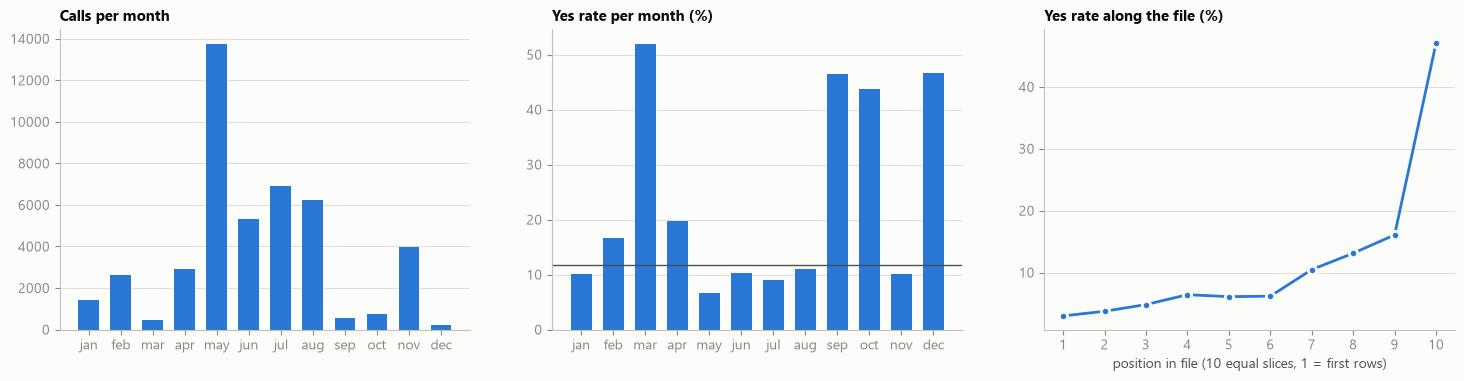

Yes rate (%) in each tenth of the file, first rows to last rows:
 1   2   3   4   5   6    7    8    9    10
3.0 3.7 4.8 6.4 6.1 6.2 10.5 13.1 16.1 47.1


month,jan,feb,mar,apr,may,jun,jul,aug,sep,oct,nov,dec
calls,1403.0,2649.0,477.0,2932.0,13766.0,5341.0,6895.0,6247.0,579.0,738.0,3970.0,214.0
yes_rate,10.1,16.6,52.0,19.7,6.7,10.2,9.1,11.0,46.5,43.8,10.2,46.7


In [5]:
# 1) The file is in chronological order: the month column runs through the calendar in blocks.
month_runs = df["month"].loc[df["month"].ne(df["month"].shift())].tolist()
print(f"{len(month_runs)} consecutive month blocks, in file order:")
print(" ".join(month_runs))

# 2) Calls and yes rate per month, in calendar order.
month_order = ["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"]
by_month = y.groupby(df["month"]).agg(calls="size", yes_rate="mean").reindex(month_order)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 3.9))
ax1.bar(by_month.index, by_month["calls"], color=BLUE, width=0.65)
ax1.set_title("Calls per month")
ax2.bar(by_month.index, by_month["yes_rate"] * 100, color=BLUE, width=0.65)
ax2.axhline(base_rate * 100, color=INK_2, lw=1)
ax2.set_title("Yes rate per month (%)")
slice_rate = y.groupby(pd.qcut(np.arange(len(df)), 10, labels=False)).mean() * 100
ax3.plot(np.arange(1, 11), slice_rate, color=BLUE, lw=2, marker="o", ms=6, mfc=BLUE, mec=SURFACE, mew=2)
ax3.set_xticks(np.arange(1, 11))
ax3.set_xlabel("position in file (10 equal slices, 1 = first rows)")
ax3.set_title("Yes rate along the file (%)")
for ax in (ax1, ax2, ax3):
    ax.grid(axis="x", visible=False)
plt.show()

print("Yes rate (%) in each tenth of the file, first rows to last rows:")
print((slice_rate.round(1)).to_frame().T.rename(columns=lambda c: c + 1).to_string(index=False))
by_month.assign(yes_rate=(by_month["yes_rate"] * 100).round(1)).T

In [6]:
# 3) contact = 'unknown' is a leftover of the early part of the file, not something a user can choose.
contact = y.groupby(df["contact"]).agg(rows="size", yes_rate="mean")
contact["share_of_rows"] = contact["rows"] / len(df)
contact["share_of_first_half"] = df["contact"].iloc[: len(df) // 2].value_counts(normalize=True)
contact["share_of_second_half"] = df["contact"].iloc[len(df) // 2:].value_counts(normalize=True)
contact.round(3)

,rows,yes_rate,share_of_rows,share_of_first_half,share_of_second_half
contact,,,,,
cellular,29285,0.149,0.648,0.400,0.896
telephone,2906,0.134,0.064,0.039,0.090
unknown,13020,0.041,0.288,0.561,0.015


>- The months run through the calendar in 30 consecutive blocks, so the row order is the time order. The yes rate climbs along the file from 3.0% in the first tenth to 47.1% in the last.
>- Some months are tiny and extreme: mar, sep, oct and dec have 44-52% yes but only 214-738 calls. may has 13,766 calls at 6.7%.
>- `contact = unknown` (13,020 rows, 4.1% yes) belongs to the early part of the file: it is 56% of the first half and 1.5% of the second. It is a data-collection leftover, not a choice a user can make.
>
>So `day`, `month` and `contact` describe when and how a call happened, not who the customer is. A random split puts rows from every period on both sides, so the model can learn "this month looks like that month". That looks like skill, but it is not available for a customer who is called later.

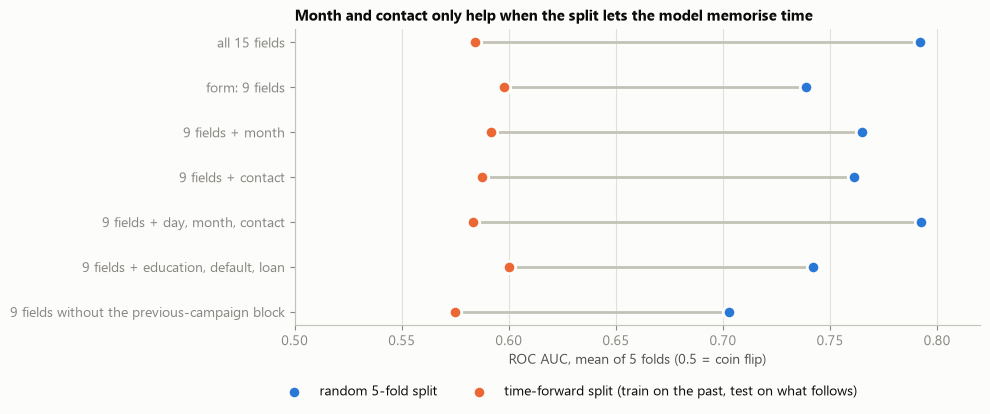

,fields,random AUC,random PR-AUC,time-forward AUC,"time-forward AUC, worst fold","time-forward AUC, best fold"
feature set,,,,,,
all 15 fields,15,0.792,0.436,0.584,0.524,0.662
form: 9 fields,9,0.739,0.383,0.598,0.541,0.671
9 fields + month,10,0.765,0.413,0.592,0.535,0.683
9 fields + contact,10,0.761,0.395,0.588,0.515,0.672
"9 fields + day, month, contact",12,0.792,0.436,0.583,0.530,0.653
"9 fields + education, default, loan",12,0.742,0.385,0.600,0.546,0.674
9 fields without the previous-campaign block,6,0.703,0.270,0.575,0.544,0.634


In [7]:
def make_pipeline(**forest_params):
    """Text columns are one-hot encoded, numeric columns pass through, then a random forest.
    Everything lives in one Pipeline, so the encoding is fitted on training data only
    and the API receives the raw form values."""
    prep = ColumnTransformer(
        [("categorical", OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
          make_column_selector(dtype_exclude=np.number))],
        remainder="passthrough",
    )
    forest = RandomForestClassifier(random_state=RANDOM_STATE, **forest_params)
    return Pipeline([("prep", prep), ("forest", forest)])


FORM_FEATURES = ["age", "job", "marital", "balance", "housing", "campaign", "pdays", "previous", "poutcome"]
PREVIOUS_CAMPAIGN = ["pdays", "previous", "poutcome"]
ALL_FEATURES = [c for c in df.columns if c not in ("y", "duration")]  # duration is only known after the call

feature_sets = {
    "all 15 fields": ALL_FEATURES,
    "form: 9 fields": FORM_FEATURES,
    "9 fields + month": FORM_FEATURES + ["month"],
    "9 fields + contact": FORM_FEATURES + ["contact"],
    "9 fields + day, month, contact": FORM_FEATURES + ["day", "month", "contact"],
    "9 fields + education, default, loan": FORM_FEATURES + ["education", "default", "loan"],
    "9 fields without the previous-campaign block": [c for c in FORM_FEATURES if c not in PREVIOUS_CAMPAIGN],
}

# Same forest settings for every row, so only the feature set changes.
COMPARE_FOREST = dict(n_estimators=200, max_depth=10, min_samples_leaf=10, max_features="sqrt", n_jobs=-1)
random_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
forward_cv = TimeSeriesSplit(n_splits=5)  # expanding window: always train on the past, test on what follows

rows = []
for name, cols in feature_sets.items():
    random_scores = cross_validate(make_pipeline(**COMPARE_FOREST), df[cols], y, cv=random_cv,
                                   scoring=["roc_auc", "average_precision"])
    forward_scores = cross_validate(make_pipeline(**COMPARE_FOREST), df[cols], y, cv=forward_cv, scoring="roc_auc")
    rows.append({"feature set": name, "fields": len(cols),
                 "random AUC": random_scores["test_roc_auc"].mean(),
                 "random PR-AUC": random_scores["test_average_precision"].mean(),
                 "time-forward AUC": forward_scores["test_score"].mean(),
                 "time-forward AUC, worst fold": forward_scores["test_score"].min(),
                 "time-forward AUC, best fold": forward_scores["test_score"].max()})
comparison = pd.DataFrame(rows).set_index("feature set")

fig, ax = plt.subplots(figsize=(10, 4.3))
ypos = np.arange(len(comparison))[::-1]
ax.hlines(ypos, comparison["time-forward AUC"], comparison["random AUC"], color=AXIS, lw=2)
ax.scatter(comparison["random AUC"], ypos, s=80, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3,
           label="random 5-fold split")
ax.scatter(comparison["time-forward AUC"], ypos, s=80, color=ORANGE, edgecolor=SURFACE, linewidth=2, zorder=3,
           label="time-forward split (train on the past, test on what follows)")
ax.set_yticks(ypos)
ax.set_yticklabels(comparison.index)
ax.set_xlim(0.5, 0.82)
ax.set_xlabel("ROC AUC, mean of 5 folds (0.5 = coin flip)")
ax.set_title("Month and contact only help when the split lets the model memorise time")
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.16), ncol=2)
fig.tight_layout()
plt.show()

comparison.round(3)

In [8]:
# The previous-campaign columns describe one fact: was this customer contacted before, and what happened.
none_flags = pd.DataFrame({"pdays == -1": df["pdays"] == -1,
                           "previous == 0": df["previous"] == 0,
                           "poutcome == unknown": df["poutcome"] == "unknown"})
all_three = none_flags.all(axis=1)
any_but_not_all = none_flags.any(axis=1) & ~all_three
print(f"All three say 'not contacted before': {all_three.sum():,} rows ({all_three.mean():.1%}). "
      f"Only some of them say so: {any_but_not_all.sum()} rows.")
print(f"poutcome == 'success' with previous == 0: {((df['poutcome'] == 'success') & (df['previous'] == 0)).sum()} rows "
      "(a form that hard-codes previous = 0 can never produce a realistic 'success').")
print()
print("Yes rate by previous-campaign outcome:")
print(y.groupby(df["poutcome"]).agg(rows="size", yes_rate="mean").round(3))

All three say 'not contacted before': 36,954 rows (81.7%). Only some of them say so: 5 rows.
poutcome == 'success' with previous == 0: 0 rows (a form that hard-codes previous = 0 can never produce a realistic 'success').

Yes rate by previous-campaign outcome:
           rows  yes_rate
poutcome                 
failure    4901     0.126
other      1840     0.167
success    1511     0.647
unknown   36959     0.092


In [9]:
# What the 15-field model does with the hidden fields: the same customer, scored in different months and contact types.
model_15 = make_pipeline(**COMPARE_FOREST).fit(df[ALL_FEATURES], y)
customer = {"age": 40, "job": "admin.", "marital": "married", "education": "secondary", "default": "no",
            "balance": 1500, "housing": "yes", "loan": "no", "contact": "cellular", "day": 15, "month": "may",
            "campaign": 1, "pdays": -1, "previous": 0, "poutcome": "unknown"}

by_month_score = pd.Series({m: model_15.predict_proba(pd.DataFrame([{**customer, "month": m}])[ALL_FEATURES])[0, 1]
                            for m in month_order}, name="predicted yes probability")
by_contact_score = pd.Series({c: model_15.predict_proba(pd.DataFrame([{**customer, "contact": c}])[ALL_FEATURES])[0, 1]
                              for c in ["cellular", "telephone", "unknown"]}, name="predicted yes probability")
print("Same customer, only the month changes:")
print(by_month_score.round(3).to_frame().T.to_string())
print("\nSame customer, only the contact type changes:")
print(by_contact_score.round(3).to_frame().T.to_string())

Same customer, only the month changes:
                             jan    feb    mar    apr    may    jun    jul    aug    sep    oct    nov    dec
predicted yes probability  0.097  0.124  0.331  0.108  0.094  0.225  0.089  0.099  0.295  0.265  0.108  0.218

Same customer, only the contact type changes:
                           cellular  telephone  unknown
predicted yes probability     0.094      0.068    0.038


**Decision: nine form fields**

>`age, job, marital, balance, housing, campaign, pdays, previous, poutcome`. Every field the model uses is a field the form asks for; nothing is hidden or hard-coded.
>
>| Feature set | random AUC | time-forward AUC |
>|---|---|---|
>| all 15 fields (without `duration`) | 0.792 | 0.584 |
>| **the 9 form fields** | **0.739** | **0.598** |
>| 9 + month | 0.765 | 0.592 |
>| 9 + contact | 0.761 | 0.588 |
>| 9 + day, month, contact | 0.792 | 0.583 |
>| 9 + education, default, loan | 0.742 | 0.600 |
>| 9 without the previous-campaign block | 0.703 | 0.575 |
>
>- Adding `day`, `month` and `contact` back lifts the random AUC to exactly the 15-field level (0.792), while the time-forward AUC does not improve (0.583). That gain is memorised time.
>- `education`, `default` and `loan` add nothing in either split (0.742 and 0.600 against 0.739 and 0.598), so they are dropped.
>- The previous-campaign block (`pdays`, `previous`, `poutcome`) stays: without it the random PR-AUC falls from 0.383 to 0.270 and the time-forward AUC from 0.598 to 0.575. The three columns describe one fact, an earlier contact and how it ended: `pdays = -1`, `previous = 0` and `poutcome = unknown` agree in 36,954 rows, with 5 exceptions. The API checks that they agree.
>- The same customer scored by the 15-field forest: the month alone moves the score from 0.09 (may, aug) to 0.33 (mar), and the contact type from 0.09 (cellular) to 0.04 (unknown).

# 4. Train, validation and test split

In [10]:
# Why not simply hold out the last part of the file? Its yes rate is nothing like the early part's.
cut = int(len(df) * 0.7)
print(f"Chronological 70/30 split: yes rate {y.iloc[:cut].mean():.1%} in the first 70% of the file, "
      f"{y.iloc[cut:].mean():.1%} in the last 30%.")

Chronological 70/30 split: yes rate 5.8% in the first 70% of the file, 25.4% in the last 30%.


In [11]:
X = df[FORM_FEATURES]

# 60 % train / 20 % validation / 20 % test, all stratified on the target.
#   train       fit models, tune hyperparameters (cross-validation inside train)
#   validation  compare models, check calibration, choose the decision threshold
#   test        touched once, at the end
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=0.25, stratify=y_dev,
                                                  random_state=RANDOM_STATE)

pd.DataFrame({"rows": [len(y_train), len(y_val), len(y_test)],
              "yes rate": [y_train.mean(), y_val.mean(), y_test.mean()]},
             index=["train", "validation", "test"]).round(4)

,rows,yes rate
train,27126,0.117
validation,9042,0.117
test,9043,0.117


>- A chronological holdout does not work here: the first 70% of the file has a 5.8% yes rate, the last 30% has 25.4%. A model trained on the first part would be judged on a different population.
>- So the main evaluation is a stratified random split: 60% train (27,126 rows), 20% validation (9,042), 20% test (9,043), each with the 11.7% base rate.
>- Train: fit and tune. Validation: compare models, check calibration, choose the threshold. Test: used once, at the end.
>- A random split is optimistic for this data (section 3). Section 9 measures by how much.

# 5. Models and hyperparameter search

In [12]:
def score_table(probas, y_true):
    """Ranking quality (AUC, PR-AUC) and probability quality (Brier, log loss, mean prediction)."""
    rows = {}
    for name, p in probas.items():
        p = np.clip(p, 1e-6, 1 - 1e-6)
        rows[name] = {"AUC": roc_auc_score(y_true, p), "PR-AUC": average_precision_score(y_true, p),
                      "Brier": brier_score_loss(y_true, p), "log loss": log_loss(y_true, p),
                      "mean predicted": p.mean()}
    return pd.DataFrame(rows).T.round(4)


logistic = Pipeline([
    ("prep", ColumnTransformer([
        ("categorical", OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
         make_column_selector(dtype_exclude=np.number)),
        ("numeric", StandardScaler(), make_column_selector(dtype_include=np.number)),
    ])),
    ("logistic", LogisticRegression(max_iter=1000)),
]).fit(X_train, y_train)

baseline = {"constant (training base rate)": np.full(len(y_val), y_train.mean())}
score_table({**baseline, "logistic regression": logistic.predict_proba(X_val)[:, 1]}, y_val)

,AUC,PR-AUC,Brier,log loss,mean predicted
constant (training base rate),0.5000,0.1170,0.1033,0.3609,0.1170
logistic regression,0.7203,0.3576,0.0894,0.3155,0.1176


In [13]:
# Hyperparameter search on the training part only, scored by PR-AUC (average precision),
# which cares about the rare "yes" class far more than accuracy or AUC does.
param_space = {
    "forest__n_estimators": [100, 200, 300],
    "forest__max_depth": [6, 8, 10, 12],
    "forest__min_samples_leaf": [5, 10, 20, 40],
    "forest__max_features": ["sqrt", 0.5, 1.0],
    "forest__class_weight": [None, "balanced_subsample"],
}
search = RandomizedSearchCV(
    make_pipeline(n_jobs=1),  # the saved model predicts one row at a time, threads would only slow it down
    param_space, n_iter=30, scoring="average_precision",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1, random_state=RANDOM_STATE,
)
search.fit(X_train, y_train)

results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
results.columns = [c.replace("param_forest__", "") for c in results.columns]
display_cols = ["n_estimators", "max_depth", "min_samples_leaf", "max_features", "class_weight",
                "mean_test_score", "std_test_score"]
print("Top 6 of 30 candidates (5-fold PR-AUC on the training part):")
results[display_cols].head(6).round(4).reset_index(drop=True)

Top 6 of 30 candidates (5-fold PR-AUC on the training part):


,n_estimators,max_depth,min_samples_leaf,max_features,class_weight,mean_test_score,std_test_score
0,300,10,10,sqrt,None,0.3701,0.0038
1,300,8,20,0.5,None,0.3699,0.0048
2,300,12,10,sqrt,None,0.3693,0.0034
3,100,10,10,sqrt,None,0.3689,0.0039
4,300,12,20,sqrt,None,0.3684,0.0047
5,200,10,5,sqrt,None,0.3683,0.0047


In [14]:
best_model = search.best_estimator_
print("Selected:", {k.replace("forest__", ""): v for k, v in search.best_params_.items()})

p_val = best_model.predict_proba(X_val)[:, 1]
score_table({**baseline,
             "logistic regression": logistic.predict_proba(X_val)[:, 1],
             "random forest (tuned)": p_val}, y_val)

Selected: {'n_estimators': 300, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 10, 'class_weight': None}


,AUC,PR-AUC,Brier,log loss,mean predicted
constant (training base rate),0.5000,0.1170,0.1033,0.3609,0.1170
logistic regression,0.7203,0.3576,0.0894,0.3155,0.1176
random forest (tuned),0.7472,0.4053,0.0862,0.3041,0.1175


>Two baselines on the validation part: a constant prediction (AUC 0.5, PR-AUC 0.117, which is the base rate) and a logistic regression built the same way (AUC 0.720, PR-AUC 0.358).
>
>The random forest search tried 30 settings with 5-fold cross-validation on the training part, scored by PR-AUC, which looks at the rare yes class where accuracy and AUC do not. The top six are within 0.002 of each other (0.368-0.370, fold-to-fold spread about 0.004), so no single setting is clearly best. What they share is that none uses class weights. Selected: 300 trees, depth 10, at least 10 rows per leaf, `sqrt` features.
>
>On the validation part the tuned forest reaches AUC 0.747 and PR-AUC 0.405, ahead of the logistic regression (0.720 and 0.358).

# 6. Can the probabilities be read as probabilities?

In [15]:
# Can the probabilities be trusted as probabilities? Compare the tuned forest with calibrated copies of it,
# and with the same forest trained with class_weight='balanced' (the setting the first version of this project used).
sigmoid = CalibratedClassifierCV(clone(best_model), method="sigmoid", cv=5, ensemble=False).fit(X_train, y_train)
isotonic = CalibratedClassifierCV(clone(best_model), method="isotonic", cv=5, ensemble=False).fit(X_train, y_train)
balanced = clone(best_model).set_params(forest__class_weight="balanced").fit(X_train, y_train)

val_probas = {
    "random forest (tuned)": p_val,
    "+ sigmoid calibration": sigmoid.predict_proba(X_val)[:, 1],
    "+ isotonic calibration": isotonic.predict_proba(X_val)[:, 1],
    "same forest, class_weight='balanced'": balanced.predict_proba(X_val)[:, 1],
}
print(f"true yes rate on the validation part: {y_val.mean():.3f}, "
      f"mean prediction of the tuned forest: {p_val.mean():.3f}")
assert abs(p_val.mean() - y_val.mean()) < 0.01, "the forest is no longer calibrated on average"
score_table(val_probas, y_val)

true yes rate on the validation part: 0.117, mean prediction of the tuned forest: 0.117


,AUC,PR-AUC,Brier,log loss,mean predicted
random forest (tuned),0.7472,0.4053,0.0862,0.3041,0.1175
+ sigmoid calibration,0.7472,0.4053,0.0868,0.3068,0.1179
+ isotonic calibration,0.7463,0.3907,0.0858,0.3031,0.1178
"same forest, class_weight='balanced'",0.7468,0.4077,0.1759,0.5403,0.4102


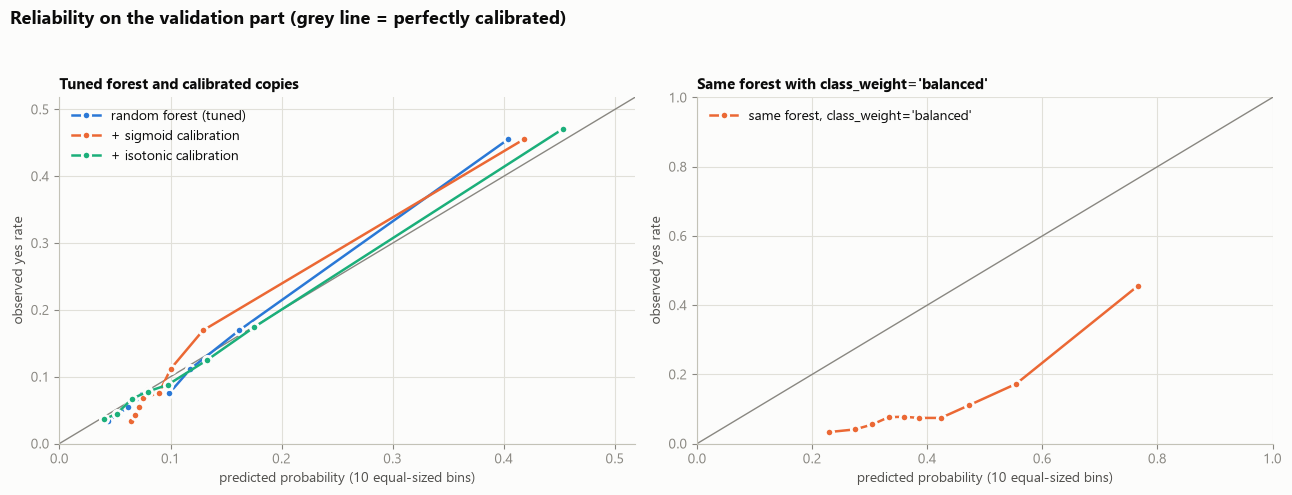

In [16]:
curves = {name: calibration_curve(y_val, p, n_bins=10, strategy="quantile") for name, p in val_probas.items()}
tuned_names = ["random forest (tuned)", "+ sigmoid calibration", "+ isotonic calibration"]
tuned_limit = 1.1 * max(max(*curves[n][0], *curves[n][1]) for n in tuned_names)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
for ax, names, colors, lim, title in [
    (ax1, tuned_names, [BLUE, ORANGE, AQUA], tuned_limit, "Tuned forest and calibrated copies"),
    (ax2, ["same forest, class_weight='balanced'"], [ORANGE], 1.0, "Same forest with class_weight='balanced'"),
]:
    ax.plot([0, lim], [0, lim], color=MUTED, lw=1)
    for name, color in zip(names, colors):
        observed, predicted = curves[name]
        ax.plot(predicted, observed, color=color, lw=1.8, marker="o", ms=6, mfc=color, mec=SURFACE, mew=2, label=name)
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel("predicted probability (10 equal-sized bins)")
    ax.set_ylabel("observed yes rate")
    ax.set_title(title)
    ax.legend(loc="upper left")
fig.suptitle("Reliability on the validation part (grey line = perfectly calibrated)", x=0.01, ha="left",
             fontsize=13, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

>The API returns `probability_of_yes`, so the probabilities should mean something.
>
>- The tuned forest, trained on the real class mix, predicts a mean of 0.1175 against a true 0.117, and its reliability curve follows the diagonal. It is a little low for the highest scores (about 0.40 predicted, 0.45 observed).
>- Sigmoid and isotonic calibration change little (Brier 0.0868 and 0.0858 against 0.0862), and isotonic lowers PR-AUC (0.391 against 0.405). They are not worth an extra step, so the saved model is the plain forest inside the pipeline.
>- The first version of this project used `class_weight='balanced'`. The ranking is the same (AUC 0.747), the probabilities are not: the mean prediction is 0.410 against a true 0.117 and the Brier score is 0.176. A score of about 0.77 from that model corresponded to roughly 45% in reality.

# 7. Decision threshold

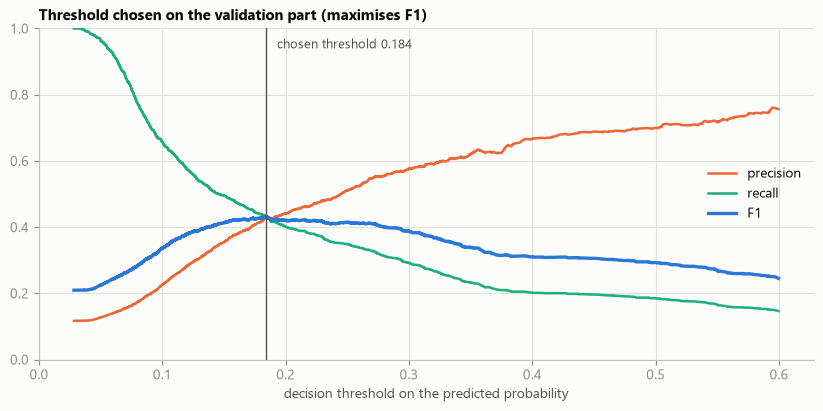

,share of customers flagged,precision,recall,F1
threshold,,,,
0.100,0.340,0.226,0.657,0.336
0.150,0.163,0.355,0.495,0.413
0.184,0.118,0.429,0.434,0.431
0.250,0.080,0.511,0.349,0.415
0.300,0.059,0.578,0.291,0.387
0.400,0.036,0.667,0.202,0.310


In [17]:
precision, recall, thresholds = precision_recall_curve(y_val, p_val)
precision, recall = precision[:-1], recall[:-1]
f1 = 2 * precision * recall / (precision + recall + 1e-12)
THRESHOLD = float(thresholds[f1.argmax()])

fig, ax = plt.subplots(figsize=(10, 4.3))
mask = thresholds <= 0.6
ax.plot(thresholds[mask], precision[mask], color=ORANGE, lw=1.8, label="precision")
ax.plot(thresholds[mask], recall[mask], color=AQUA, lw=1.8, label="recall")
ax.plot(thresholds[mask], f1[mask], color=BLUE, lw=2.4, label="F1")
ax.axvline(THRESHOLD, color=INK_2, lw=1)
ax.annotate(f"chosen threshold {THRESHOLD:.3f}", (THRESHOLD, 0.97), xytext=(8, 0), textcoords="offset points",
            va="top", color=INK_2, fontsize=9)
ax.set_xlabel("decision threshold on the predicted probability")
ax.set_ylim(0, 1)
ax.set_title("Threshold chosen on the validation part (maximises F1)")
ax.legend(loc="center right")
plt.show()

candidates = sorted({0.10, 0.15, round(THRESHOLD, 3), 0.25, 0.30, 0.40})
rows = []
for t in candidates:
    flagged = p_val >= t
    rows.append({"threshold": t, "share of customers flagged": flagged.mean(),
                 "precision": y_val[flagged].mean(), "recall": y_val[flagged].sum() / y_val.sum(),
                 "F1": f1_score(y_val, flagged)})
pd.DataFrame(rows).set_index("threshold").round(3)

>The threshold maximises F1 on the validation part: **0.184**. It is not 0.5, and it is not tuned on the test part. At 0.184 the validation precision is 0.429 and the recall 0.435.
>
>- Lower thresholds call many more customers and find more subscribers, but most calls fail: at 0.10, 34% of customers are flagged, with recall 0.657 and precision 0.226.
>- Higher thresholds are surer but miss most subscribers: at 0.40, 3.6% are flagged, with precision 0.667 and recall 0.202.
>- Because the probabilities are calibrated, the threshold reads directly: call a customer when the model gives them at least an 18% chance, about 1.6 times the base rate.
>
>Which point is right is a business decision (cost of a call against the value of a subscription). F1 is a neutral default.

# 8. Final evaluation on the test part

In [18]:
# The only time the test part is used: one evaluation of the chosen model at the chosen threshold.
p_test = best_model.predict_proba(X_test)[:, 1]
flagged = p_test >= THRESHOLD
tn, fp, fn, tp = confusion_matrix(y_test, flagged).ravel()
yt = y_test.to_numpy()

rng = np.random.default_rng(RANDOM_STATE)
boot = []
for _ in range(1000):  # bootstrap the test rows to see how much these numbers could move
    i = rng.integers(0, len(yt), len(yt))
    boot.append([roc_auc_score(yt[i], p_test[i]), average_precision_score(yt[i], p_test[i]),
                 f1_score(yt[i], flagged[i]), yt[i][flagged[i]].mean(), flagged[i][yt[i] == 1].mean()])
low, high = np.percentile(boot, [2.5, 97.5], axis=0)

point = [roc_auc_score(yt, p_test), average_precision_score(yt, p_test), f1_score(yt, flagged),
         tp / (tp + fp), tp / (tp + fn)]
test_report = pd.DataFrame({"test": point, "95% CI low": low, "95% CI high": high},
                           index=["AUC", "PR-AUC", f"F1 at {THRESHOLD:.3f}", f"precision at {THRESHOLD:.3f}",
                                  f"recall at {THRESHOLD:.3f}"])
print(f"{len(yt):,} test rows, {yt.sum():,} subscribers. Flagged {flagged.mean():.1%} of customers.")
print(f"accuracy {(tn + tp) / len(yt):.3f}  (always 'no': {1 - yt.mean():.3f})")
print(f"confusion matrix: TN={tn:,} FP={fp:,} FN={fn:,} TP={tp:,}")
test_report.round(3)

9,043 test rows, 1,058 subscribers. Flagged 11.6% of customers.
accuracy 0.864  (always 'no': 0.883)
confusion matrix: TN=7,372 FP=613 FN=619 TP=439


,test,95% CI low,95% CI high
AUC,0.749,0.732,0.767
PR-AUC,0.385,0.354,0.419
F1 at 0.184,0.416,0.391,0.440
precision at 0.184,0.417,0.387,0.446
recall at 0.184,0.415,0.386,0.443


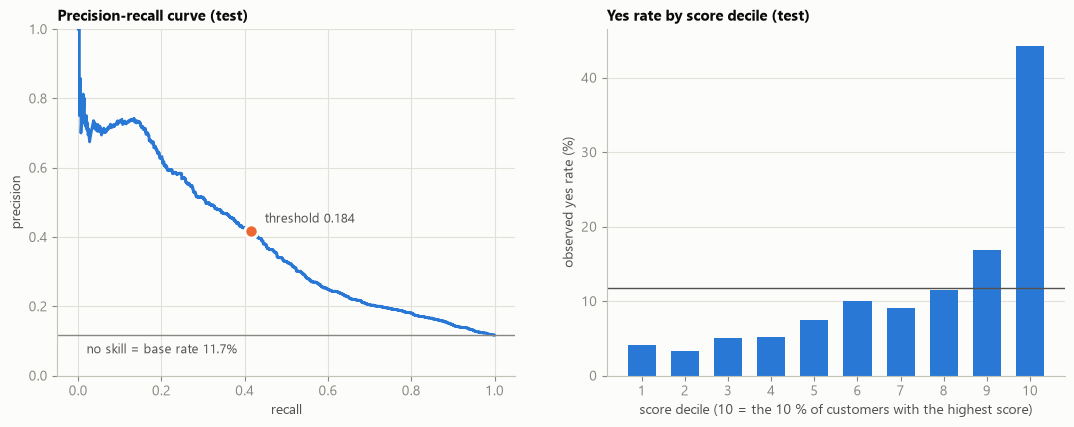

Top decile: 44.3% subscribe, 3.8x the overall rate.


In [19]:
decile = pd.qcut(pd.Series(p_test).rank(method="first"), 10, labels=False)
decile_rate = pd.Series(yt).groupby(decile.to_numpy()).mean() * 100
top_decile_rate = decile_rate.iloc[-1]

pr_precision, pr_recall, _ = precision_recall_curve(yt, p_test)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(pr_recall, pr_precision, color=BLUE, lw=2)
ax1.axhline(yt.mean(), color=MUTED, lw=1)
ax1.annotate(f"no skill = base rate {yt.mean():.1%}", (0.02, yt.mean()), xytext=(0, -6), textcoords="offset points",
             va="top", color=INK_2, fontsize=9)
ax1.scatter([tp / (tp + fn)], [tp / (tp + fp)], s=90, color=ORANGE, edgecolor=SURFACE, linewidth=2, zorder=3)
ax1.annotate(f"threshold {THRESHOLD:.3f}", (tp / (tp + fn), tp / (tp + fp)), xytext=(10, 6),
             textcoords="offset points", color=INK_2, fontsize=9)
ax1.set_xlabel("recall")
ax1.set_ylabel("precision")
ax1.set_ylim(0, 1)
ax1.set_title("Precision-recall curve (test)")

ax2.bar(np.arange(1, 11), decile_rate, color=BLUE, width=0.65)
ax2.axhline(yt.mean() * 100, color=INK_2, lw=1)
ax2.set_xticks(np.arange(1, 11))
ax2.set_xlabel("score decile (10 = the 10 % of customers with the highest score)")
ax2.set_ylabel("observed yes rate (%)")
ax2.set_title("Yes rate by score decile (test)")
ax2.grid(axis="x", visible=False)
plt.show()

print(f"Top decile: {top_decile_rate:.1f}% subscribe, {top_decile_rate / (yt.mean() * 100):.1f}x the overall rate.")

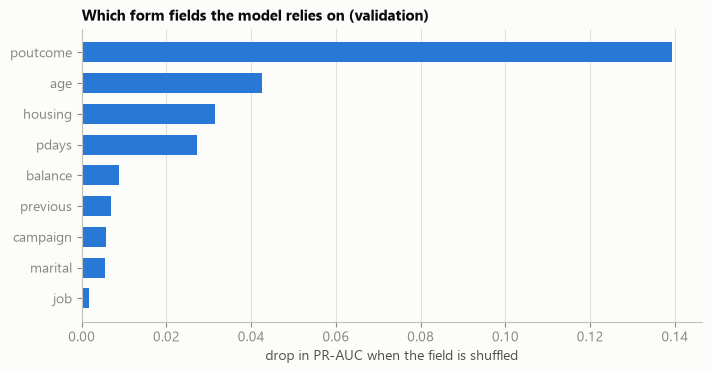

In [20]:
# Permutation importance on the validation part, per form field (shuffle one column, see how much PR-AUC drops).
importance = permutation_importance(best_model, X_val, y_val, scoring="average_precision",
                                    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(importance.importances_mean, index=X_val.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(importance.index, importance.values, color=BLUE, height=0.65)
ax.set_xlabel("drop in PR-AUC when the field is shuffled")
ax.set_title("Which form fields the model relies on (validation)")
ax.grid(axis="y", visible=False)
plt.show()

>The test part is used once, with the model and the threshold fixed beforehand. The 95% intervals come from bootstrapping the test rows.
>
>- AUC 0.749 (0.732-0.767) and PR-AUC 0.385 (0.354-0.419), about 3.3 times the PR-AUC of 0.117 that a model without skill gets.
>- At 0.184 the model flags 11.6% of customers: precision 0.417, recall 0.415, F1 0.416. Of 1,058 subscribers it finds 439 and misses 619, and it flags 613 customers who do not subscribe.
>- Accuracy is 0.864, below the 0.883 of always answering "no". Accuracy is the wrong yardstick for an 88/12 split and is shown only for that comparison.
>- The 10% of customers with the highest scores subscribe at 44.3%, 3.8 times the overall rate. That is the practical use: put the customers worth calling first.
>- Permutation importance on the validation part: `poutcome` matters most by far, then `age`, `housing` and `pdays`. `job` adds almost nothing.

# 9. How far to trust these numbers: a time-forward check

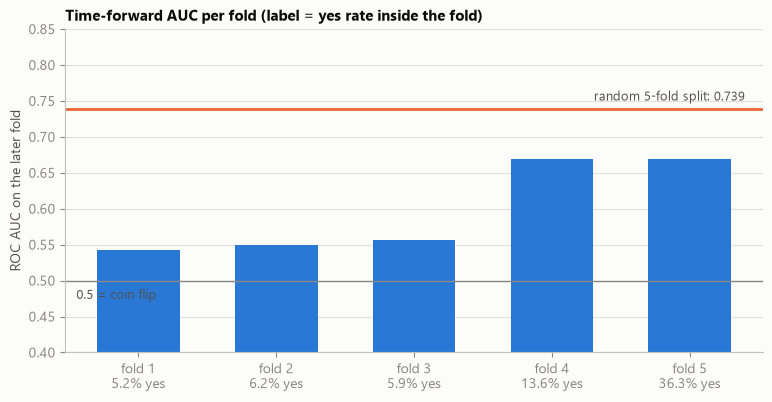

,training rows,test fold yes rate,AUC
fold 1,7536,0.052,0.543
fold 2,15071,0.062,0.549
fold 3,22606,0.059,0.556
fold 4,30141,0.136,0.670
fold 5,37676,0.363,0.669


In [21]:
# Same tuned pipeline, but the test fold always lies AFTER the training rows in the file.
forward = cross_validate(clone(best_model), X, y, cv=forward_cv, scoring="roc_auc", n_jobs=-1)
random_auc = cross_validate(clone(best_model), X, y, cv=random_cv, scoring="roc_auc", n_jobs=-1)["test_score"].mean()

fold_rates = [y.iloc[test].mean() for _, test in forward_cv.split(X)]
fold_train_rows = [len(train) for train, _ in forward_cv.split(X)]
tick_labels = [f"fold {i}\n{r:.1%} yes" for i, r in enumerate(fold_rates, start=1)]

fig, ax = plt.subplots(figsize=(9, 4.2))
ax.bar(tick_labels, forward["test_score"], color=BLUE, width=0.6)
ax.axhline(random_auc, color=ORANGE, lw=2)
ax.annotate(f"random 5-fold split: {random_auc:.3f}", (4.4, random_auc), xytext=(0, 6), textcoords="offset points",
            ha="right", color=INK_2, fontsize=9)
ax.axhline(0.5, color=MUTED, lw=1)
ax.annotate("0.5 = coin flip", (-0.45, 0.5), xytext=(0, -6), textcoords="offset points", va="top",
            color=INK_2, fontsize=9)
ax.set_ylim(0.4, 0.85)
ax.set_ylabel("ROC AUC on the later fold")
ax.set_title("Time-forward AUC per fold (label = yes rate inside the fold)")
ax.grid(axis="x", visible=False)
plt.show()

pd.DataFrame({"training rows": fold_train_rows, "test fold yes rate": fold_rates,
              "AUC": forward["test_score"]}, index=[f"fold {i}" for i in range(1, 6)]).round(3)

>A random split puts rows from every period on both sides. A customer called next month is different: the model only knows the past. Here the tuned model is trained on an expanding window of the earlier rows and tested on the block that follows.
>
>- AUC per fold: 0.543, 0.549, 0.556, 0.670, 0.669, mean 0.597. The random 5-fold AUC of the same model is 0.739.
>- The first three folds are close to 0.55, not far above a coin flip. The yes rate inside the folds goes from about 6% (folds 1-3) to 13.6% and 36.3% (folds 4 and 5), so the population itself changes along the file.
>- Read 0.75 as the ranking quality for customers drawn from the same mix as the training file, and 0.55-0.67 as the range to expect if the customer mix shifts over time. This data cannot say which of the two a real deployment would see.
>- This is also why `day`, `month` and `contact` are not in the form (section 3).

# 10. Refit and export

In [22]:
# Refit on every row with the selected settings. The threshold stays the one chosen on the validation part.
final_model = clone(best_model).fit(X, y)
assert final_model.named_steps["forest"].n_jobs == 1

# Sanity check of the refit before it is saved. Scores on rows the model was trained on are too confident,
# so only their average is compared with the base rate. The flagged share is compared out-of-fold,
# on models that never saw the rows they score, against the share flagged on the validation part.
p_refit = final_model.predict_proba(X)[:, 1]
p_out_of_fold = cross_val_predict(clone(best_model), X, y, cv=random_cv, method="predict_proba")[:, 1]
print(f"mean prediction of the refit on all rows: {p_refit.mean():.3f} (base rate {base_rate:.3f})")
print(f"share flagged at {THRESHOLD:.3f}: {(p_val >= THRESHOLD).mean():.1%} on the validation part, "
      f"{(p_out_of_fold >= THRESHOLD).mean():.1%} out-of-fold on all rows")
assert abs(p_refit.mean() - base_rate) < 0.01

API_DIR = Path("../backend-api")  # outside the repo (e.g. on Kaggle) the files go to the working directory
model_dir = API_DIR / "models" if API_DIR.exists() else Path(".")
config_dir = API_DIR / "config" if API_DIR.exists() else Path(".")
model_dir.mkdir(exist_ok=True)
config_dir.mkdir(exist_ok=True)

flagged_val = p_val >= THRESHOLD
validation_at_threshold = {"precision": float(y_val[flagged_val].mean()),
                           "recall": float(y_val[flagged_val].sum() / y_val.sum()),
                           "f1": float(f1_score(y_val, flagged_val))}


def save_artifacts(model, threshold):
    """Writes the single model file and the threshold file the API loads."""
    with open(model_dir / "bank_marketing_rf_model.pkl", "wb") as file:
        pickle.dump(model, file)
    info = {
        "optimal_threshold": threshold,
        "selection_rule": "maximises F1 on the validation part (probabilities are not class-weighted)",
        "validation_precision": validation_at_threshold["precision"],
        "validation_recall": validation_at_threshold["recall"],
        "validation_f1": validation_at_threshold["f1"],
        "form_fields": list(model.feature_names_in_),
        "trained_on_rows": int(len(X)),
        "scikit_learn": sklearn.__version__,
        "numpy": np.__version__,
    }
    with open(config_dir / "optimal_threshold.json", "w") as file:
        json.dump(info, file, indent=4)
    return info


saved = save_artifacts(final_model, THRESHOLD)
print(json.dumps(saved, indent=2))

# Reload from disk and check it gives the same answer as the model in memory.
with open(model_dir / "bank_marketing_rf_model.pkl", "rb") as file:
    reloaded = pickle.load(file)
example = pd.DataFrame([{"age": 40, "job": "admin.", "marital": "divorced", "balance": 1500.0, "housing": "no",
                         "campaign": 1, "pdays": -1, "previous": 0, "poutcome": "unknown"}])
in_memory, from_disk = final_model.predict_proba(example)[0, 1], reloaded.predict_proba(example)[0, 1]
assert in_memory == from_disk
print(f"\nExample customer: P(yes) = {from_disk:.4f}, flagged = {from_disk >= THRESHOLD}")

mean prediction of the refit on all rows: 0.117 (base rate 0.117)
share flagged at 0.184: 11.9% on the validation part, 11.9% out-of-fold on all rows
{
  "optimal_threshold": 0.1839082828913721,
  "selection_rule": "maximises F1 on the validation part (probabilities are not class-weighted)",
  "validation_precision": 0.4291044776119403,
  "validation_recall": 0.43478260869565216,
  "validation_f1": 0.431924882629108,
  "form_fields": [
    "age",
    "job",
    "marital",
    "balance",
    "housing",
    "campaign",
    "pdays",
    "previous",
    "poutcome"
  ],
  "trained_on_rows": 45211,
  "scikit_learn": "1.6.1",
  "numpy": "2.4.6"
}

Example customer: P(yes) = 0.1412, flagged = False


**What the saved files contain**

>- `bank_marketing_rf_model.pkl`: one pipeline (one-hot encoding and the random forest, with `n_jobs=1` because the API scores one row at a time), refit on all 45,211 rows with the settings selected above.
>- `optimal_threshold.json`: the threshold 0.184 chosen on the validation part, its validation precision, recall and F1, and the numpy and scikit-learn versions that wrote the pickle.
>- Checks before saving: the mean prediction of the refit (0.117) matches the base rate, and the share flagged at 0.184 is the same out-of-fold on all rows (11.9%) as on the validation part (11.9%). A reload from disk gives the same answer as the model in memory.
>
>**Figures to quote**: test AUC 0.749 and PR-AUC 0.385, precision 0.417 and recall 0.415 at the 0.184 threshold, top-decile subscription rate 44.3% (3.8 times the base rate). These describe the model trained on 60% of the rows; the saved pickle is refit on all rows, so it has no untouched holdout of its own. Expect lower numbers over time (section 9).